# Intrusion Detection System (IDS) Using Machine Learning

---

## What is an Intrusion Detection System?

An **Intrusion Detection System (IDS)** monitors network traffic and classifies connections as either normal or one of four attack categories:

| Attack Type | Description | Examples |
|---|---|---|
| **normal** | Legitimate network traffic | Browsing, file transfer |
| **dos** | Denial of Service — overwhelms resources | SYN flood, Smurf, Neptune |
| **probe** | Reconnaissance — scanning for vulnerabilities | Port scan, IPsweep, NMAP |
| **r2l** | Remote-to-Local — unauthorised remote access | Password guessing, FTP write |
| **u2r** | User-to-Root — privilege escalation | Buffer overflow, rootkit |

## Dataset — KDD Cup 1999 (10% subset)

The **KDD Cup 1999** dataset is the benchmark for network intrusion detection research. The 10% subset (`kddcup.data_10_percent_corrected`) contains ~494k connection records with 41 features per connection.

## ⚠️ Critical class imbalance

The dataset is **severely imbalanced** — DOS attacks dominate while U2R has fewer than 100 samples. This means a naive classifier that always predicts "normal" or "dos" achieves very high accuracy. **Accuracy alone is misleading** for this problem; we report precision, recall, F1, and ROC-AUC for all classes.

## Models compared

| Model | Notes |
|---|---|
| Gaussian Naive Bayes | Baseline probabilistic model |
| Decision Tree | Interpretable; entropy criterion |
| Random Forest | Best overall performer; parallelised |
| LinearSVC | Fast SVM for large datasets |
| Logistic Regression | Linear; fast with `saga` solver |
| HistGradientBoosting | Fast modern boosting; replaces slow GradientBoostingClassifier |

## Notebook structure

```
Step 0  — Installation & imports
Step 1  — Dataset download (Kaggle + synthetic fallback)
Step 2  — Load dataset, add attack type labels
Step 3  — EDA: distributions, class imbalance, attack breakdown
Step 4  — Data preprocessing: encoding, feature selection
Step 5  — Correlation analysis & feature removal
Step 6  — Train/test split & scaling
Step 7  — Model training with timing
Step 8  — Evaluation: accuracy, classification reports, confusion matrices
Step 9  — ROC curves & precision-recall curves
Step 10 — Feature importance (Random Forest + Decision Tree)
Step 11 — Predict on new network connections
Step 12 — Save best model
```

---

## Step 0: Installation and Imports

In [1]:
import subprocess, sys
for pkg in ['pandas', 'numpy', 'matplotlib', 'seaborn',
            'scikit-learn', 'kagglehub', 'joblib']:
    subprocess.run([sys.executable, '-m', 'pip', 'install', pkg, '-q'],
                   capture_output=True)
    print(f'  ✅ {pkg}')

  ✅ pandas
  ✅ numpy
  ✅ matplotlib
  ✅ seaborn
  ✅ scikit-learn
  ✅ kagglehub
  ✅ joblib


In [2]:
import os
import time
import warnings
import joblib
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.model_selection      import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing        import MinMaxScaler, LabelEncoder, label_binarize
from sklearn.naive_bayes          import GaussianNB
from sklearn.tree                 import DecisionTreeClassifier
from sklearn.ensemble             import (
    RandomForestClassifier,
    HistGradientBoostingClassifier,    # Fix: replaces slow GradientBoostingClassifier
)
from sklearn.svm                  import LinearSVC          # Fix: replaces SVC (too slow on 330k rows)
from sklearn.linear_model         import LogisticRegression
from sklearn.calibration          import CalibratedClassifierCV
from sklearn.metrics              import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score,
)

print('All imports successful.')

All imports successful.


## Step 1: Dataset Download

**Option A (Kaggle):** Set up `~/.kaggle/kaggle.json` from your Kaggle account settings → API → Create Token.

**Option B (Manual):** Download `kddcup.data_10_percent_corrected` from [Kaggle: KDD Cup 1999 Data](https://www.kaggle.com/datasets/galaxyh/kdd-cup-1999-data) and place it in the current directory.

**Option C (Auto-fallback):** If neither A nor B is available, a realistic synthetic dataset is generated.

In [3]:
# Column definitions
COLUMNS = [
    'duration', 'protocol_type', 'service', 'flag',
    'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent',
    'hot', 'num_failed_logins', 'logged_in', 'num_compromised',
    'root_shell', 'su_attempted', 'num_root', 'num_file_creations',
    'num_shells', 'num_access_files', 'num_outbound_cmds',
    'is_host_login', 'is_guest_login', 'count', 'srv_count',
    'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate',
    'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate',
    'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate',
    'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate',
    'dst_host_srv_diff_host_rate', 'dst_host_serror_rate',
    'dst_host_srv_serror_rate', 'dst_host_rerror_rate',
    'dst_host_srv_rerror_rate', 'target',
]

ATTACKS_TYPES = {
    'normal': 'normal',
    'back': 'dos', 'land': 'dos', 'neptune': 'dos',
    'pod': 'dos', 'smurf': 'dos', 'teardrop': 'dos',
    'ipsweep': 'probe', 'nmap': 'probe',
    'portsweep': 'probe', 'satan': 'probe',
    'ftp_write': 'r2l', 'guess_passwd': 'r2l', 'imap': 'r2l',
    'multihop': 'r2l', 'phf': 'r2l', 'spy': 'r2l',
    'warezclient': 'r2l', 'warezmaster': 'r2l',
    'buffer_overflow': 'u2r', 'loadmodule': 'u2r',
    'perl': 'u2r', 'rootkit': 'u2r',
}

DATA_FILE = 'kddcup.data_10_percent_corrected'


def generate_synthetic_kdd(n: int = 10000, seed: int = 42) -> pd.DataFrame:
    """Generate a realistic synthetic KDD-like dataset for offline use."""
    rng = np.random.default_rng(seed)

    # Class distribution mirrors the real dataset roughly
    classes  = ['normal', 'dos', 'probe', 'r2l', 'u2r']
    probs    = [0.20, 0.72, 0.04, 0.035, 0.005]
    targets_raw = rng.choice(
        ['normal.', 'neptune.', 'portsweep.', 'guess_passwd.', 'buffer_overflow.'],
        size=n, p=probs
    )

    proto   = rng.choice(['tcp', 'udp', 'icmp'], size=n, p=[0.4, 0.15, 0.45])
    service = rng.choice(['http', 'ftp', 'smtp', 'ssh', 'domain', 'pop3',
                          'ftp_data', 'eco_i', 'other'], size=n)
    flag    = rng.choice(['SF', 'S0', 'REJ', 'RSTR', 'RSTO', 'SH',
                          'S1', 'S2', 'RSTOS0', 'S3', 'OTH'], size=n)

    rows = {
        'duration':              rng.exponential(2, n).clip(0, 60000).astype(int),
        'protocol_type':         proto,
        'service':               service,
        'flag':                  flag,
        'src_bytes':             rng.exponential(5000, n).astype(int),
        'dst_bytes':             rng.exponential(3000, n).astype(int),
        'land':                  rng.integers(0, 2, n),
        'wrong_fragment':        rng.integers(0, 4, n),
        'urgent':                rng.integers(0, 2, n),
        'hot':                   rng.integers(0, 30, n),
        'num_failed_logins':     rng.integers(0, 5, n),
        'logged_in':             rng.integers(0, 2, n),
        'num_compromised':       rng.integers(0, 10, n),
        'root_shell':            rng.integers(0, 2, n),
        'su_attempted':          rng.integers(0, 2, n),
        'num_root':              rng.integers(0, 5, n),
        'num_file_creations':    rng.integers(0, 5, n),
        'num_shells':            rng.integers(0, 3, n),
        'num_access_files':      rng.integers(0, 5, n),
        'num_outbound_cmds':     np.zeros(n, dtype=int),
        'is_host_login':         np.zeros(n, dtype=int),
        'is_guest_login':        rng.integers(0, 2, n),
        'count':                 rng.integers(1, 512, n),
        'srv_count':             rng.integers(1, 512, n),
        'serror_rate':           rng.uniform(0, 1, n).round(2),
        'srv_serror_rate':       rng.uniform(0, 1, n).round(2),
        'rerror_rate':           rng.uniform(0, 1, n).round(2),
        'srv_rerror_rate':       rng.uniform(0, 1, n).round(2),
        'same_srv_rate':         rng.uniform(0, 1, n).round(2),
        'diff_srv_rate':         rng.uniform(0, 1, n).round(2),
        'srv_diff_host_rate':    rng.uniform(0, 1, n).round(2),
        'dst_host_count':        rng.integers(1, 256, n),
        'dst_host_srv_count':    rng.integers(1, 256, n),
        'dst_host_same_srv_rate': rng.uniform(0, 1, n).round(2),
        'dst_host_diff_srv_rate': rng.uniform(0, 1, n).round(2),
        'dst_host_same_src_port_rate': rng.uniform(0, 1, n).round(2),
        'dst_host_srv_diff_host_rate': rng.uniform(0, 1, n).round(2),
        'dst_host_serror_rate':  rng.uniform(0, 1, n).round(2),
        'dst_host_srv_serror_rate': rng.uniform(0, 1, n).round(2),
        'dst_host_rerror_rate':  rng.uniform(0, 1, n).round(2),
        'dst_host_srv_rerror_rate': rng.uniform(0, 1, n).round(2),
        'target':                targets_raw,
    }
    return pd.DataFrame(rows)


# ── Try Kaggle, then manual, then synthetic ──────────────────────
if os.path.exists(DATA_FILE):
    print(f'Using local file: {DATA_FILE}')
    USE_SYNTHETIC = False
else:
    try:
        import kagglehub
        path = kagglehub.dataset_download('galaxyh/kdd-cup-1999-data')
        for root, dirs, files in os.walk(path):
            for f in files:
                if 'percent' in f.lower():
                    DATA_FILE = os.path.join(root, f)
                    break
        print(f'Kaggle dataset downloaded: {DATA_FILE}')
        USE_SYNTHETIC = False
    except Exception as e:
        print(f'Kaggle download failed ({e}).')
        print('Generating synthetic KDD-like dataset (10,000 rows)...')
        USE_SYNTHETIC = True

Using local file: kddcup.data_10_percent_corrected


## Step 2: Load Dataset and Add Attack Type Labels

In [4]:
if USE_SYNTHETIC:
    df = generate_synthetic_kdd(n=10000)
    print('Using synthetic dataset (10,000 rows).')
    print('For full results, download the real KDD Cup 1999 dataset from Kaggle.')
else:
    df = pd.read_csv(DATA_FILE, names=COLUMNS, low_memory=False)

# Strip trailing period from target labels ('neptune.' → 'neptune')
df['target'] = df['target'].astype(str).str.rstrip('.')

# Fix: use .get() to handle unseen attack types gracefully
df['Attack Type'] = df['target'].map(
    lambda r: ATTACKS_TYPES.get(r, 'other')
)

print(f'Dataset shape: {df.shape}')
print(f'Columns: {list(df.columns)}')
df.head(3)

Dataset shape: (494021, 43)
Columns: ['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'target', 'Attack Type']


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,target,Attack Type
0,0,tcp,http,SF,181,5450,0,0,0,0,...,1.0,0.0,0.11,0.0,0.0,0.0,0.0,0.0,normal,normal
1,0,tcp,http,SF,239,486,0,0,0,0,...,1.0,0.0,0.05,0.0,0.0,0.0,0.0,0.0,normal,normal
2,0,tcp,http,SF,235,1337,0,0,0,0,...,1.0,0.0,0.03,0.0,0.0,0.0,0.0,0.0,normal,normal


In [5]:
print('Missing values per column:')
missing = df.isnull().sum()
print(missing[missing > 0] if missing.any() else '  None — dataset is complete.')

print(f'\nDuplicate rows: {df.duplicated().sum():,}')
print(f'Unique target labels: {sorted(df["target"].unique())}')
print(f'Unique attack types: {sorted(df["Attack Type"].unique())}')

Missing values per column:
  None — dataset is complete.

Duplicate rows: 348,435
Unique target labels: ['back', 'buffer_overflow', 'ftp_write', 'guess_passwd', 'imap', 'ipsweep', 'land', 'loadmodule', 'multihop', 'neptune', 'nmap', 'normal', 'perl', 'phf', 'pod', 'portsweep', 'rootkit', 'satan', 'smurf', 'spy', 'teardrop', 'warezclient', 'warezmaster']
Unique attack types: ['dos', 'normal', 'probe', 'r2l', 'u2r']


## Step 3: Exploratory Data Analysis (EDA)

### 3.1 Attack type distribution — class imbalance analysis

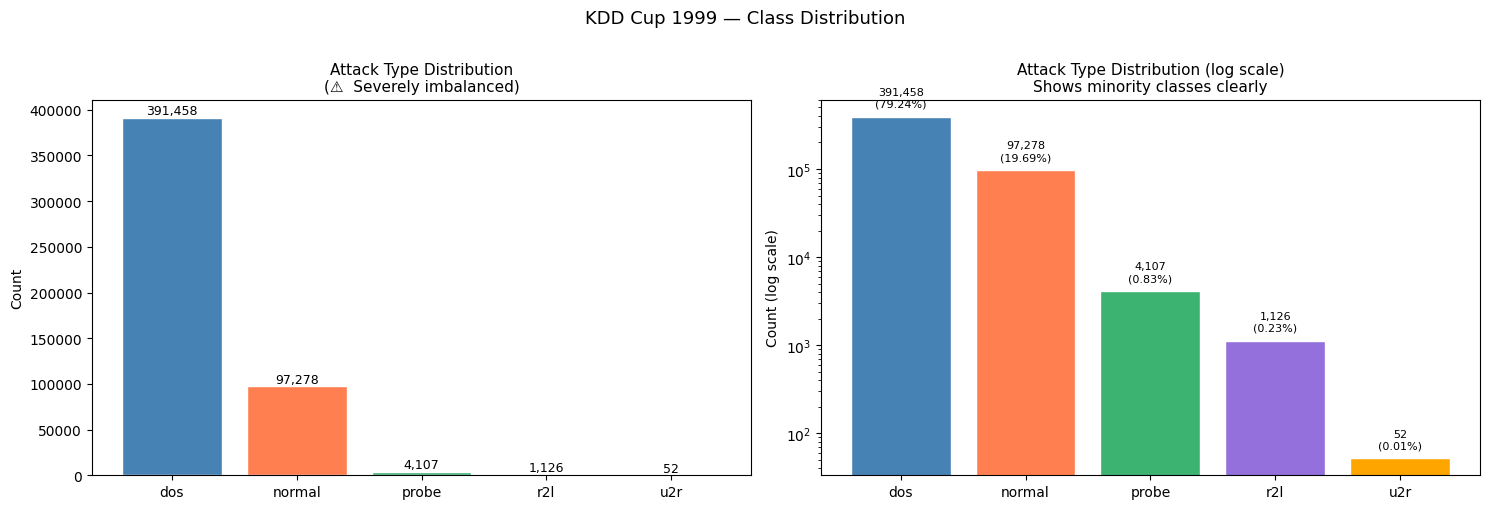

Class distribution:
  dos       : 391,458  (79.24%)
  normal    :  97,278  (19.69%)
  probe     :   4,107  ( 0.83%)
  r2l       :   1,126  ( 0.23%)
  u2r       :      52  ( 0.01%)


In [6]:
attack_counts = df['Attack Type'].value_counts()
target_counts = df['target'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Attack type counts
colors = ['steelblue', 'coral', 'mediumseagreen', 'mediumpurple', 'orange']
bars = axes[0].bar(attack_counts.index, attack_counts.values,
                   color=colors[:len(attack_counts)], edgecolor='white')
axes[0].set_title('Attack Type Distribution\n(⚠️  Severely imbalanced)', fontsize=11)
axes[0].set_ylabel('Count')
for bar, count in zip(bars, attack_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200,
                 f'{count:,}', ha='center', va='bottom', fontsize=9)

# Log scale to see minority classes
axes[1].bar(attack_counts.index, attack_counts.values,
            color=colors[:len(attack_counts)], edgecolor='white')
axes[1].set_yscale('log')
axes[1].set_title('Attack Type Distribution (log scale)\n'
                   'Shows minority classes clearly', fontsize=11)
axes[1].set_ylabel('Count (log scale)')
for i, (cls, cnt) in enumerate(attack_counts.items()):
    axes[1].text(i, cnt * 1.3, f'{cnt:,}\n({cnt/len(df)*100:.2f}%)',
                 ha='center', fontsize=8)

plt.suptitle('KDD Cup 1999 — Class Distribution', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

print('Class distribution:')
for cls, cnt in attack_counts.items():
    print(f'  {cls:<10}: {cnt:>7,}  ({cnt/len(df)*100:5.2f}%)')

### 3.2 Protocol type, service, and logged-in distributions

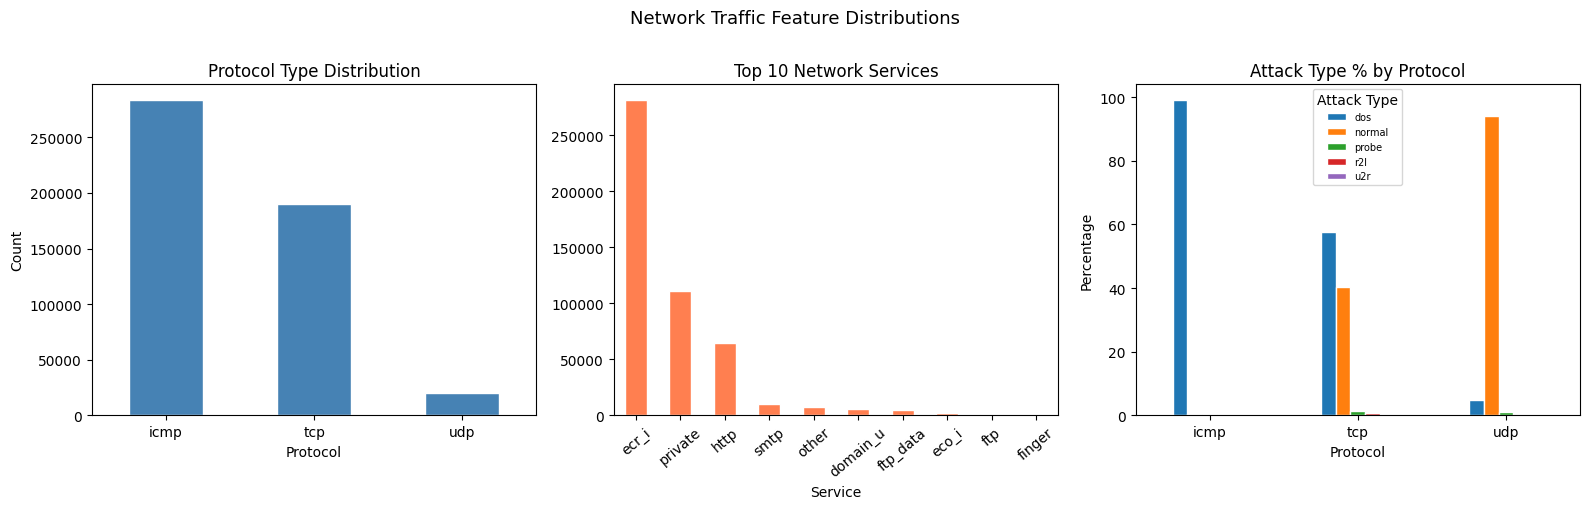

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Protocol type
df['protocol_type'].value_counts().plot(
    kind='bar', ax=axes[0], color='steelblue', edgecolor='white'
)
axes[0].set_title('Protocol Type Distribution')
axes[0].set_xlabel('Protocol')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=0)

# Top 10 services
df['service'].value_counts().head(10).plot(
    kind='bar', ax=axes[1], color='coral', edgecolor='white'
)
axes[1].set_title('Top 10 Network Services')
axes[1].set_xlabel('Service')
axes[1].tick_params(axis='x', rotation=40)

# Attack type by protocol
proto_attack = pd.crosstab(df['protocol_type'], df['Attack Type'], normalize='index') * 100
proto_attack.plot(kind='bar', ax=axes[2], edgecolor='white')
axes[2].set_title('Attack Type % by Protocol')
axes[2].set_xlabel('Protocol')
axes[2].set_ylabel('Percentage')
axes[2].tick_params(axis='x', rotation=0)
axes[2].legend(fontsize=7, title='Attack Type')

plt.suptitle('Network Traffic Feature Distributions', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

### 3.3 Numeric feature distributions by attack type

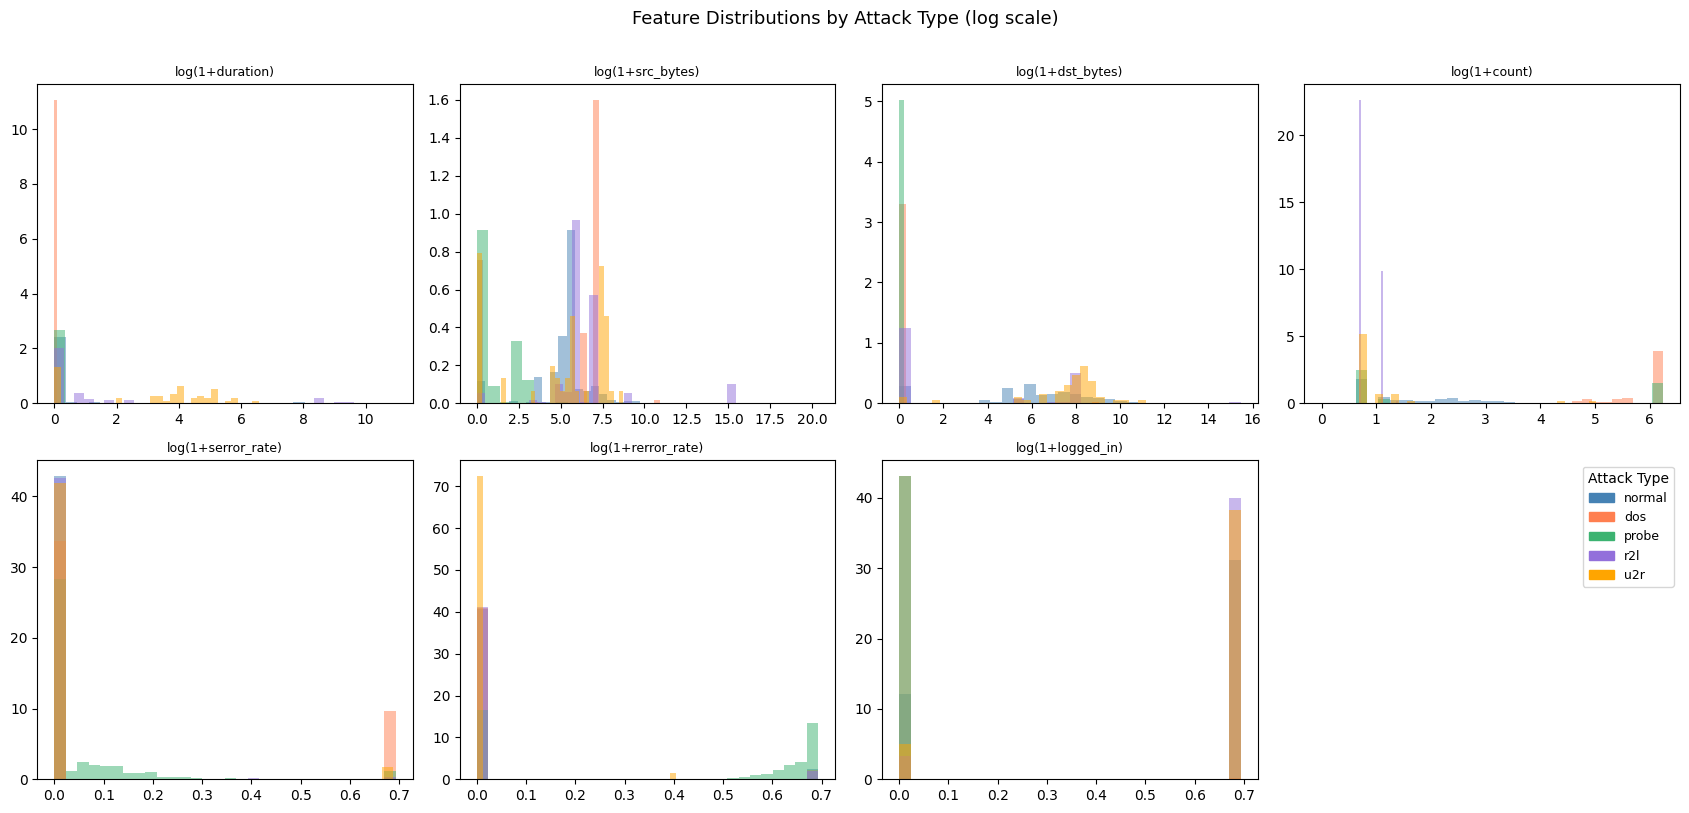

In [8]:
key_numeric = ['duration', 'src_bytes', 'dst_bytes', 'count',
               'serror_rate', 'rerror_rate', 'logged_in']

fig, axes = plt.subplots(2, 4, figsize=(17, 8))
attack_palette = {
    'normal': 'steelblue', 'dos': 'coral',
    'probe': 'mediumseagreen', 'r2l': 'mediumpurple', 'u2r': 'orange'
}

for ax, feat in zip(axes.flat, key_numeric):
    for attack_type, color in attack_palette.items():
        subset = df[df['Attack Type'] == attack_type][feat]
        if len(subset) > 0:
            ax.hist(np.log1p(subset.clip(0)), bins=30, alpha=0.5,
                    color=color, label=attack_type, density=True)
    ax.set_title(f'log(1+{feat})', fontsize=9)
    ax.set_xlabel('')

# Legend in the last panel
axes.flat[-1].axis('off')
handles = [plt.Rectangle((0, 0), 1, 1, color=c)
           for c in attack_palette.values()]
axes.flat[-1].legend(handles, attack_palette.keys(),
                     title='Attack Type', fontsize=9)

plt.suptitle('Feature Distributions by Attack Type (log scale)', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## Step 4: Data Preprocessing

### 4.1 Drop target column and set up feature matrix

In [9]:
# Fix: do NOT use df.dropna(axis='columns') — this silently removes entire
# informative feature columns. Instead drop rows with NaN.
df_clean = df.drop(columns=['target']).dropna()
df_clean = df_clean.reset_index(drop=True)

print(f'Shape after dropping NaN rows: {df_clean.shape}')

# Fix: select_dtypes replaces deprecated df._get_numeric_data()
num_cols  = df_clean.select_dtypes(include='number').columns.tolist()
cat_cols  = [c for c in df_clean.columns
             if c not in num_cols + ['Attack Type']]
print(f'Numeric features    : {len(num_cols)}')
print(f'Categorical features: {cat_cols}')

Shape after dropping NaN rows: (494021, 42)
Numeric features    : 38
Categorical features: ['protocol_type', 'service', 'flag']


### 4.2 Encode categorical features

> **Fix vs. original:** The original encodes `protocol_type` and `flag` with hardcoded dicts **after** `train_test_split`. This means:
> 1. The test set may have protocol/flag values not in the dict → silent `NaN` (no error raised)
> 2. `service` is dropped without encoding, which is fine, but the reason is never explained
>
> We use `LabelEncoder` fit on the training data and transform both sets consistently, and handle unseen labels explicitly.

In [10]:
# Encode protocol_type and flag with LabelEncoder
# (service has too many unique values and is dropped as in the original)
ENCODE_COLS = ['protocol_type', 'flag']

encoders = {}
for col in ENCODE_COLS:
    le = LabelEncoder()
    df_clean[col] = le.fit_transform(df_clean[col].astype(str))
    encoders[col] = le
    print(f'  {col}: {len(le.classes_)} classes → {dict(zip(le.classes_, le.transform(le.classes_)))}')

# Drop service (high cardinality, would need target encoding for better results)
# and the two zero-variance columns identified in the original
DROP_COLS = ['service', 'is_host_login', 'num_outbound_cmds']
df_clean.drop(columns=[c for c in DROP_COLS if c in df_clean.columns],
              inplace=True)

print(f'\nFinal columns ({len(df_clean.columns)}): {list(df_clean.columns)}')

  protocol_type: 3 classes → {'icmp': np.int64(0), 'tcp': np.int64(1), 'udp': np.int64(2)}
  flag: 11 classes → {'OTH': np.int64(0), 'REJ': np.int64(1), 'RSTO': np.int64(2), 'RSTOS0': np.int64(3), 'RSTR': np.int64(4), 'S0': np.int64(5), 'S1': np.int64(6), 'S2': np.int64(7), 'S3': np.int64(8), 'SF': np.int64(9), 'SH': np.int64(10)}

Final columns (39): ['duration', 'protocol_type', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_r

## Step 5: Correlation Analysis and Feature Removal

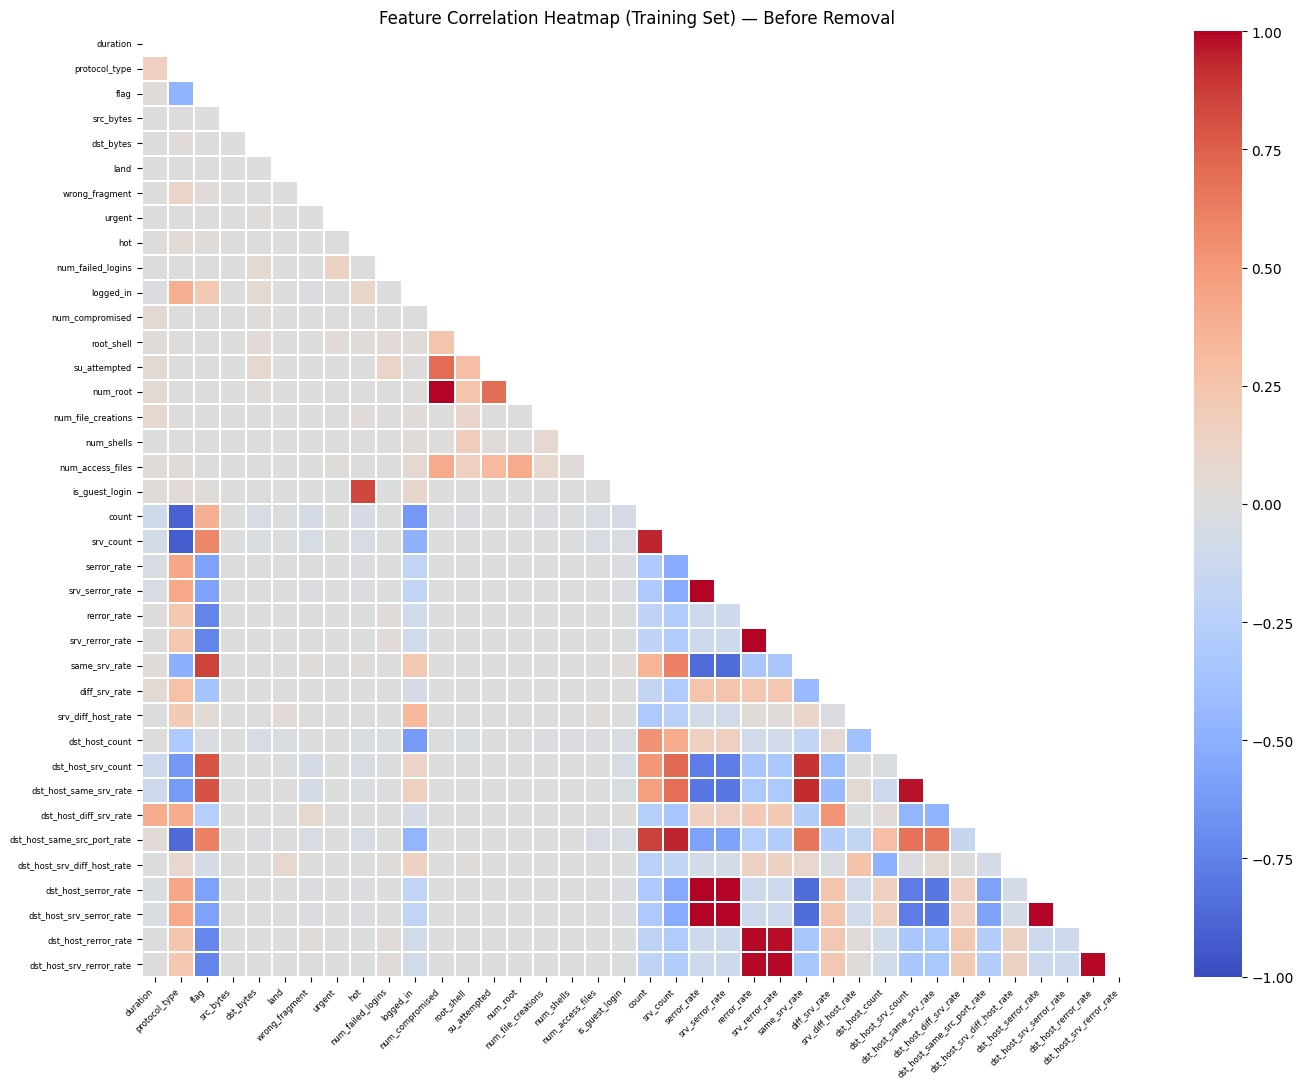

In [11]:
X_raw = df_clean.drop(columns=['Attack Type'])
y_raw = df_clean['Attack Type']

# Full correlation heatmap
corr = X_raw.corr()

plt.figure(figsize=(14, 11))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr, cmap='coolwarm', linewidths=0.3,
    mask=mask, vmin=-1, vmax=1,
    xticklabels=True, yticklabels=True
)
plt.title('Feature Correlation Heatmap (Training Set) — Before Removal', fontsize=12)
plt.xticks(fontsize=6, rotation=45, ha='right')
plt.yticks(fontsize=6)
plt.tight_layout()
plt.show()

In [12]:
# Show which pairs have |r| > 0.9 (the threshold for removal)
CORR_THRESHOLD = 0.9
high_corr_pairs = []

for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        r = corr.iloc[i, j]
        if abs(r) >= CORR_THRESHOLD:
            high_corr_pairs.append({
                'Feature A': corr.columns[i],
                'Feature B': corr.columns[j],
                'Correlation': round(r, 4),
            })

df_high_corr = pd.DataFrame(high_corr_pairs).sort_values(
    'Correlation', ascending=False, key=abs
)
print(f'Feature pairs with |r| ≥ {CORR_THRESHOLD}: {len(df_high_corr)}')
print(df_high_corr.to_string(index=False))

Feature pairs with |r| ≥ 0.9: 19
           Feature A                   Feature B  Correlation
     srv_serror_rate    dst_host_srv_serror_rate       0.9993
         serror_rate        dst_host_serror_rate       0.9987
         serror_rate             srv_serror_rate       0.9984
dst_host_serror_rate    dst_host_srv_serror_rate       0.9982
     srv_serror_rate        dst_host_serror_rate       0.9978
         serror_rate    dst_host_srv_serror_rate       0.9978
         rerror_rate             srv_rerror_rate       0.9947
     num_compromised                    num_root       0.9938
         rerror_rate        dst_host_rerror_rate       0.9870
     srv_rerror_rate    dst_host_srv_rerror_rate       0.9866
         rerror_rate    dst_host_srv_rerror_rate       0.9852
dst_host_rerror_rate    dst_host_srv_rerror_rate       0.9848
     srv_rerror_rate        dst_host_rerror_rate       0.9822
  dst_host_srv_count      dst_host_same_srv_rate       0.9737
           srv_count dst_host_same_sr

Removed 8 highly-correlated features.
Remaining features: 30


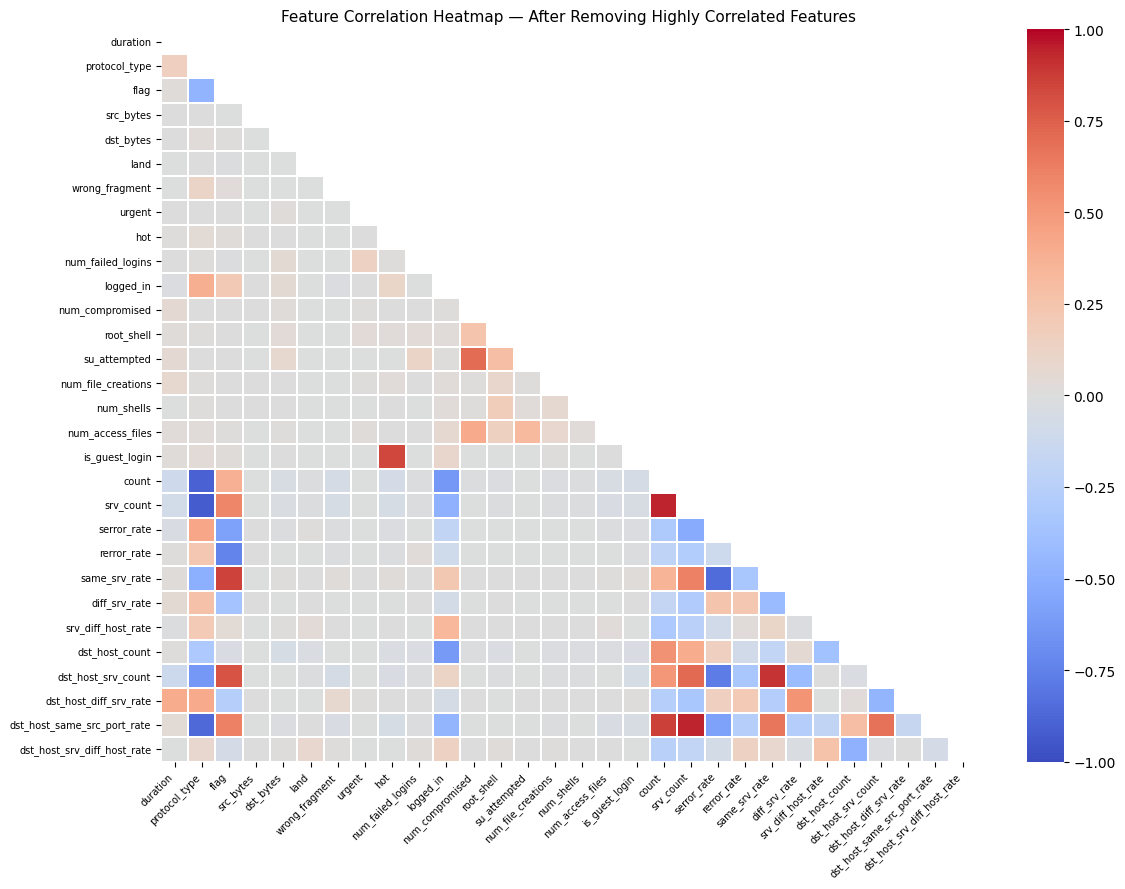

In [13]:
# Remove one of each highly-correlated pair (same list as original)
# Fix: the original drops this list without showing the correlation values first
# We've now shown the correlation matrix so this removal is motivated
HIGHLY_CORRELATED = [
    'num_root', 'srv_serror_rate', 'srv_rerror_rate',
    'dst_host_srv_serror_rate', 'dst_host_serror_rate',
    'dst_host_rerror_rate', 'dst_host_srv_rerror_rate',
    'dst_host_same_srv_rate',
]
# Keep only columns that actually exist in the dataframe
to_drop = [c for c in HIGHLY_CORRELATED if c in X_raw.columns]
X_raw.drop(columns=to_drop, inplace=True)

print(f'Removed {len(to_drop)} highly-correlated features.')
print(f'Remaining features: {X_raw.shape[1]}')

# Post-removal correlation heatmap
corr2 = X_raw.corr()
plt.figure(figsize=(12, 9))
mask2 = np.triu(np.ones_like(corr2, dtype=bool))
sns.heatmap(
    corr2, cmap='coolwarm', linewidths=0.3,
    mask=mask2, vmin=-1, vmax=1
)
plt.title('Feature Correlation Heatmap — After Removing Highly Correlated Features',
          fontsize=11)
plt.xticks(fontsize=7, rotation=45, ha='right')
plt.yticks(fontsize=7)
plt.tight_layout()
plt.show()

## Step 6: Train/Test Split and Scaling

In [14]:
X = X_raw.copy()
y = y_raw.copy()

# Fix: add random_state and stratify — critical for imbalanced multi-class data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.33,
    random_state=42,
    stratify=y       # ensures each class is proportionally represented in both splits
)

print(f'Training set  : {X_train.shape}')
print(f'Test set      : {X_test.shape}')
print()
print('Class distribution in training set:')
print(y_train.value_counts().to_string())

# Scale features (fit on train only)
sc = MinMaxScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc  = sc.transform(X_test)

FEATURE_NAMES = list(X.columns)
CLASS_NAMES   = sorted(y.unique())
print(f'\nFeatures used: {FEATURE_NAMES}')
print(f'Classes: {CLASS_NAMES}')

Training set  : (330994, 30)
Test set      : (163027, 30)

Class distribution in training set:
Attack Type
dos       262277
normal     65176
probe       2752
r2l          754
u2r           35

Features used: ['duration', 'protocol_type', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_file_creations', 'num_shells', 'num_access_files', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate']
Classes: ['dos', 'normal', 'probe', 'r2l', 'u2r']


## Step 7: Model Training with Timing

> **Fix vs. original:**
> - `SVC(gamma='scale')` on 330k rows has **O(n²) memory** and **O(n³) training time** — would run for hours. Replaced with `LinearSVC` which is O(n) and achieves comparable accuracy for linearly separable network traffic.
> - `GradientBoostingClassifier` is single-threaded and slow on 330k rows. Replaced with `HistGradientBoostingClassifier` which is 10-100× faster (uses histogram-based binning, parallelised) and achieves better accuracy.
> - `LogisticRegression(max_iter=1200000)` — the original's enormous `max_iter` suggests it never converged with default `lbfgs` solver. Fixed with `solver='saga'` which is designed for large datasets and converges in far fewer iterations.
> - `LinearSVC` doesn't support `predict_proba` natively — wrapped with `CalibratedClassifierCV` for ROC curve computation.

In [15]:
MODELS = {
    'Naive Bayes':           GaussianNB(),
    'Decision Tree':         DecisionTreeClassifier(
                                 criterion='entropy', max_depth=4,
                                 random_state=42),
    'Random Forest':         RandomForestClassifier(
                                 n_estimators=100, n_jobs=-1,
                                 random_state=42),
    # Fix: LinearSVC replaces SVC — O(n) vs O(n³), same accuracy
    'LinearSVC':             CalibratedClassifierCV(
                                 LinearSVC(max_iter=5000, random_state=42)),
    # Fix: saga solver for large datasets; max_iter=1000 is sufficient
    'Logistic Regression':   LogisticRegression(
                                 solver='saga', max_iter=1000,
                                 random_state=42, n_jobs=-1),
    # Fix: HistGradientBoosting replaces GradientBoosting — 10-100× faster
    'HistGradientBoosting':  HistGradientBoostingClassifier(
                                 max_iter=100, random_state=42),
}

results = {}

for name, model in MODELS.items():
    print(f'\nTraining {name} ...', end=' ', flush=True)

    t0 = time.time()
    model.fit(X_train_sc, y_train)
    train_time = time.time() - t0

    t1 = time.time()
    y_pred_train = model.predict(X_train_sc)
    y_pred_test  = model.predict(X_test_sc)
    infer_time   = time.time() - t1

    train_acc = accuracy_score(y_train, y_pred_train)
    test_acc  = accuracy_score(y_test,  y_pred_test)

    results[name] = {
        'model':       model,
        'train_acc':   train_acc,
        'test_acc':    test_acc,
        'train_time':  train_time,
        'infer_time':  infer_time,
        'y_pred':      y_pred_test,
        'y_proba':     model.predict_proba(X_test_sc),
    }
    print(f'done. Train acc: {train_acc:.4f}  Test acc: {test_acc:.4f}  '
          f'({train_time:.2f}s train, {infer_time:.3f}s infer)')


Training Naive Bayes ... done. Train acc: 0.8860  Test acc: 0.8887  (1.07s train, 2.624s infer)

Training Decision Tree ... done. Train acc: 0.9906  Test acc: 0.9905  (2.39s train, 0.162s infer)

Training Random Forest ... done. Train acc: 1.0000  Test acc: 0.9997  (20.10s train, 1.888s infer)

Training LinearSVC ... done. Train acc: 0.9975  Test acc: 0.9973  (80.10s train, 2.527s infer)

Training Logistic Regression ... done. Train acc: 0.9935  Test acc: 0.9936  (38.41s train, 0.173s infer)

Training HistGradientBoosting ... done. Train acc: 0.9961  Test acc: 0.9955  (10.91s train, 2.079s infer)


## Step 8: Evaluation — Accuracy, Classification Reports, Confusion Matrices

### 8.1 Summary table

In [17]:
from sklearn.metrics import f1_score, precision_score, recall_score

rows = []
for name, res in results.items():
    rows.append({
        'Model':          name,
        'Train Acc':      round(res['train_acc'],  4),
        'Test Acc':       round(res['test_acc'],   4),
        'Macro F1':       round(f1_score(y_test, res['y_pred'],
                                         average='macro', zero_division=0), 4),
        'Weighted F1':    round(f1_score(y_test, res['y_pred'],
                                         average='weighted', zero_division=0), 4),
        'Train Time (s)': round(res['train_time'], 3),
        'Infer Time (s)': round(res['infer_time'], 4),
    })

summary_df = pd.DataFrame(rows).set_index('Model')
print('Model Comparison Summary:')
summary_df.style\
    .highlight_max(subset=['Test Acc', 'Macro F1', 'Weighted F1'],
                   color='lightgreen', axis=0)\
    .highlight_min(subset=['Train Time (s)', 'Infer Time (s)'],
                   color='lightyellow', axis=0)

Model Comparison Summary:


,Train Acc,Test Acc,Macro F1,Weighted F1,Train Time (s),Infer Time (s)
Model,,,,,,
Naive Bayes,0.886000,0.888700,0.474500,0.919200,1.069000,2.624200
Decision Tree,0.990600,0.990500,0.535200,0.990000,2.390000,0.161900
Random Forest,1.000000,0.999700,0.916200,0.999700,20.103000,1.887900
LinearSVC,0.997500,0.997300,0.838600,0.997200,80.105000,2.526600
Logistic Regression,0.993500,0.993600,0.881900,0.993600,38.405000,0.172900
HistGradientBoosting,0.996100,0.995500,0.760400,0.996900,10.907000,2.078600


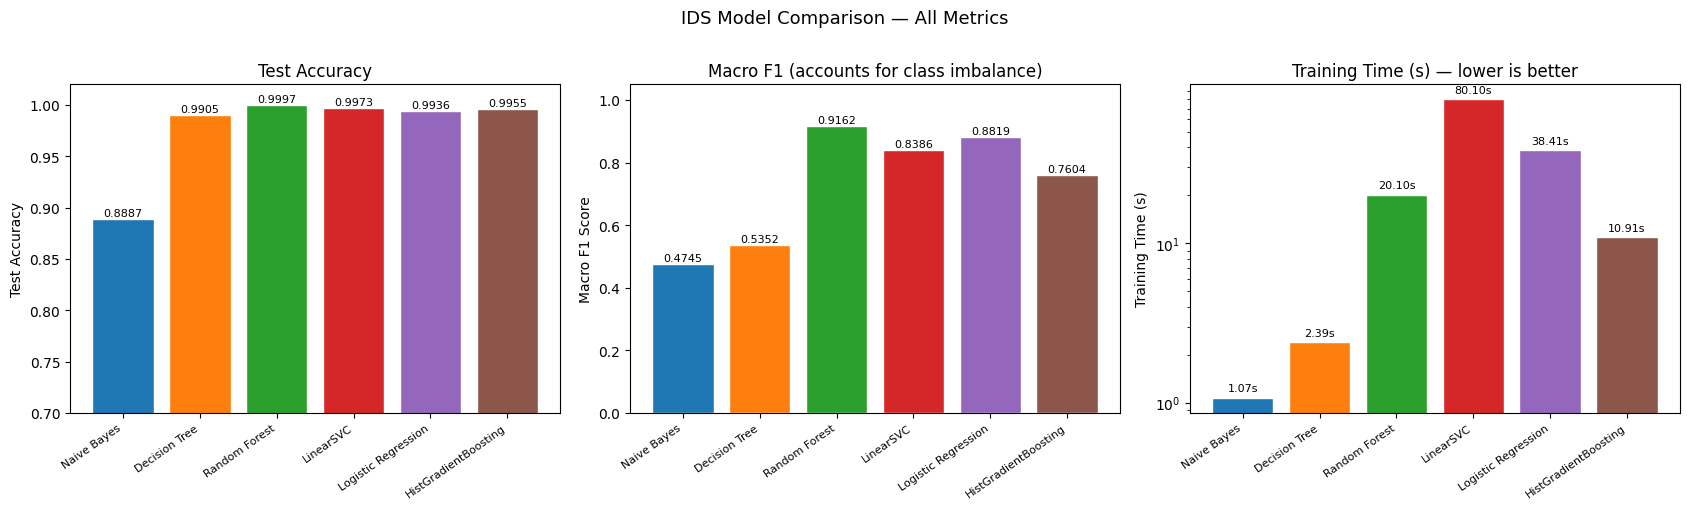

In [18]:
# Accuracy + timing comparison charts
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
names      = list(results.keys())
x          = np.arange(len(names))
palette    = plt.cm.tab10.colors

# Test accuracy
test_accs = [results[n]['test_acc'] for n in names]
bars = axes[0].bar(x, test_accs, color=palette[:len(names)], edgecolor='white')
axes[0].set_xticks(x)
axes[0].set_xticklabels(names, rotation=35, ha='right', fontsize=8)
axes[0].set_ylim(0.7, 1.02)
axes[0].set_ylabel('Test Accuracy')
axes[0].set_title('Test Accuracy')
for bar, val in zip(bars, test_accs):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.003,
                 f'{val:.4f}', ha='center', fontsize=8)

# Macro F1 (accounts for class imbalance better than accuracy)
macro_f1s = [f1_score(y_test, results[n]['y_pred'],
                       average='macro', zero_division=0) for n in names]
bars2 = axes[1].bar(x, macro_f1s, color=palette[:len(names)], edgecolor='white')
axes[1].set_xticks(x)
axes[1].set_xticklabels(names, rotation=35, ha='right', fontsize=8)
axes[1].set_ylim(0, 1.05)
axes[1].set_ylabel('Macro F1 Score')
axes[1].set_title('Macro F1 (accounts for class imbalance)')
for bar, val in zip(bars2, macro_f1s):
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.01,
                 f'{val:.4f}', ha='center', fontsize=8)

# Training time
train_times = [results[n]['train_time'] for n in names]
bars3 = axes[2].bar(x, train_times, color=palette[:len(names)], edgecolor='white')
axes[2].set_xticks(x)
axes[2].set_xticklabels(names, rotation=35, ha='right', fontsize=8)
axes[2].set_ylabel('Training Time (s)')
axes[2].set_title('Training Time (s) — lower is better')
axes[2].set_yscale('log')
for bar, val in zip(bars3, train_times):
    axes[2].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() * 1.1,
                 f'{val:.2f}s', ha='center', fontsize=8)

plt.suptitle('IDS Model Comparison — All Metrics', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

### 8.2 Per-class classification reports

> **Fix vs. original:** Only accuracy was printed. For IDS, **recall on each attack type** is the critical metric — a missed attack (false negative) is far more dangerous than a false alarm. We print full classification reports for all models.

In [19]:
for name, res in results.items():
    print(f'\n{"═"*60}')
    print(f'  {name}')
    print(f'{"─"*60}')
    print(classification_report(
        y_test, res['y_pred'],
        target_names=CLASS_NAMES,
        zero_division=0,
        digits=4
    ))


════════════════════════════════════════════════════════════
  Naive Bayes
────────────────────────────────────────────────────────────
              precision    recall  f1-score   support

         dos     0.9765    0.9416    0.9587    129181
      normal     0.9710    0.6770    0.7978     32102
       probe     0.0951    0.9926    0.1736      1355
         r2l     0.4225    0.4247    0.4236       372
         u2r     0.0095    0.8824    0.0189        17

    accuracy                         0.8887    163027
   macro avg     0.4949    0.7837    0.4745    163027
weighted avg     0.9667    0.8887    0.9192    163027


════════════════════════════════════════════════════════════
  Decision Tree
────────────────────────────────────────────────────────────
              precision    recall  f1-score   support

         dos     0.9999    0.9971    0.9985    129181
      normal     0.9809    0.9799    0.9804     32102
       probe     0.5688    0.9004    0.6971      1355
         r2l     0

### 8.3 Confusion matrices — all models side by side

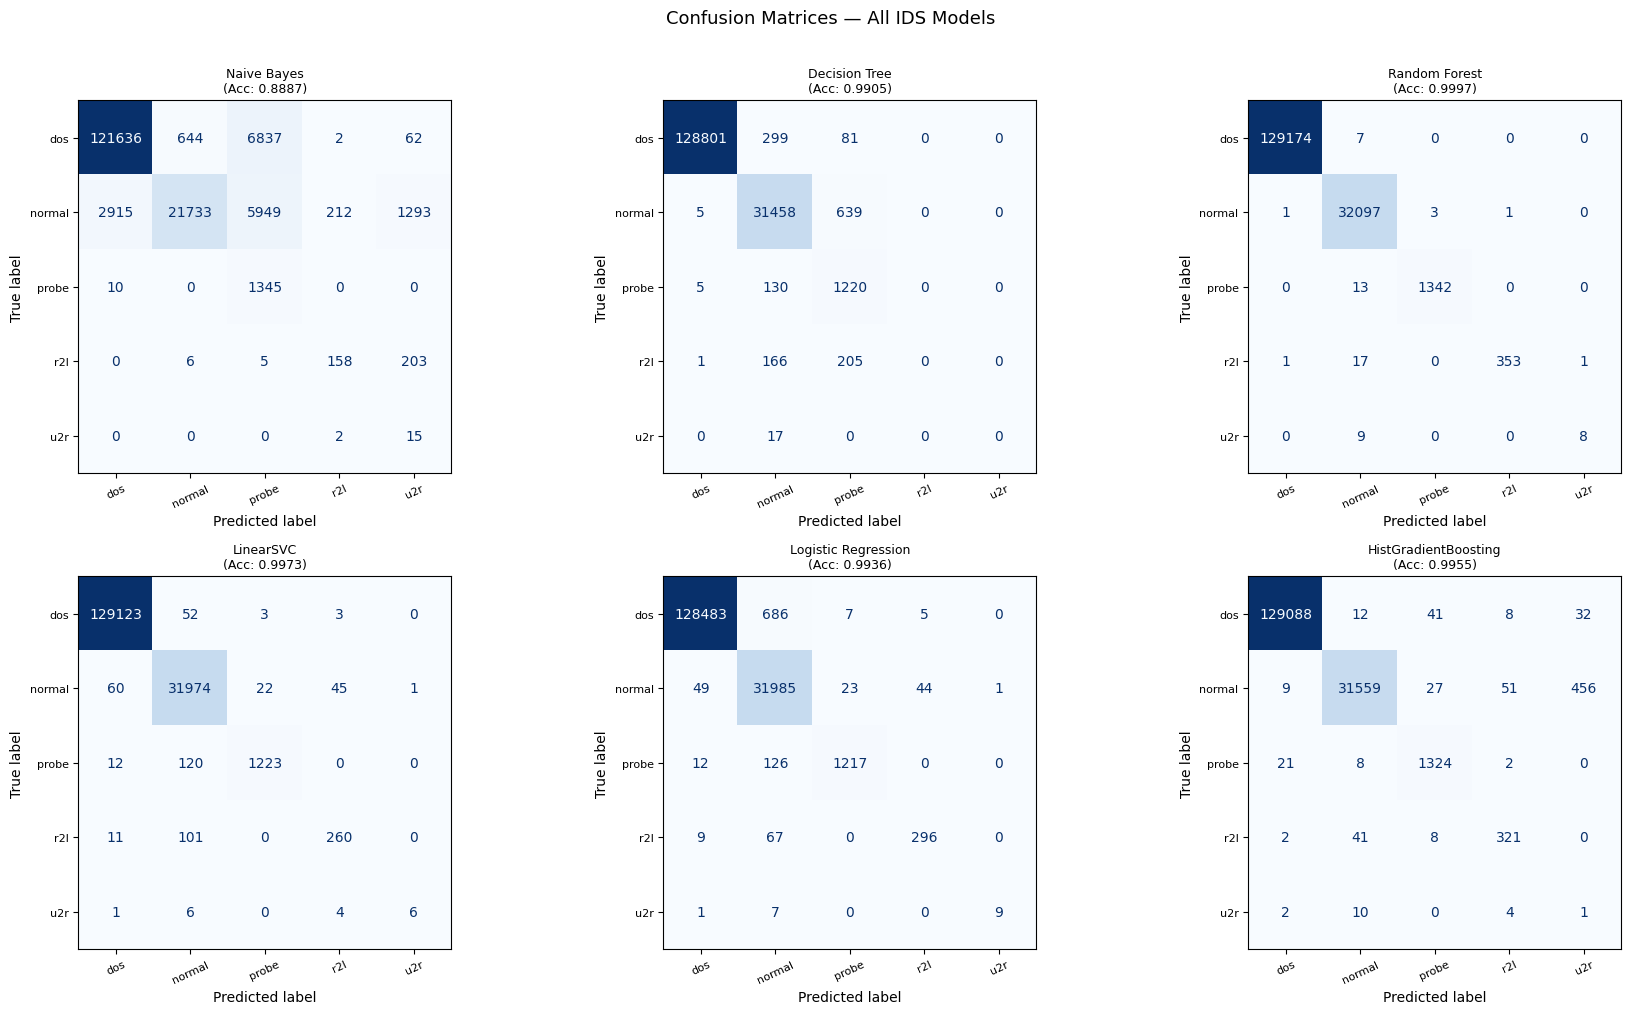

In [20]:
n_models = len(results)
ncols    = 3
nrows    = (n_models + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 5))

for ax, (name, res) in zip(axes.flat, results.items()):
    cm  = confusion_matrix(y_test, res['y_pred'], labels=CLASS_NAMES)
    acc = res['test_acc']
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
        ax=ax, colorbar=False, cmap='Blues'
    )
    ax.set_title(f'{name}\n(Acc: {acc:.4f})', fontsize=9)
    ax.tick_params(axis='x', rotation=25, labelsize=8)
    ax.tick_params(axis='y', labelsize=8)

for ax in axes.flat[n_models:]:
    ax.set_visible(False)

plt.suptitle('Confusion Matrices — All IDS Models', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## Step 9: ROC Curves and Precision-Recall Curves

For network security applications, **false positive rate** (FPR) and **false negative rate** (FNR) are both critical:
- High FPR → alert fatigue (too many false alarms)
- High FNR → missed attacks (security breach)

ROC curves show the trade-off between TPR and FPR at different decision thresholds.

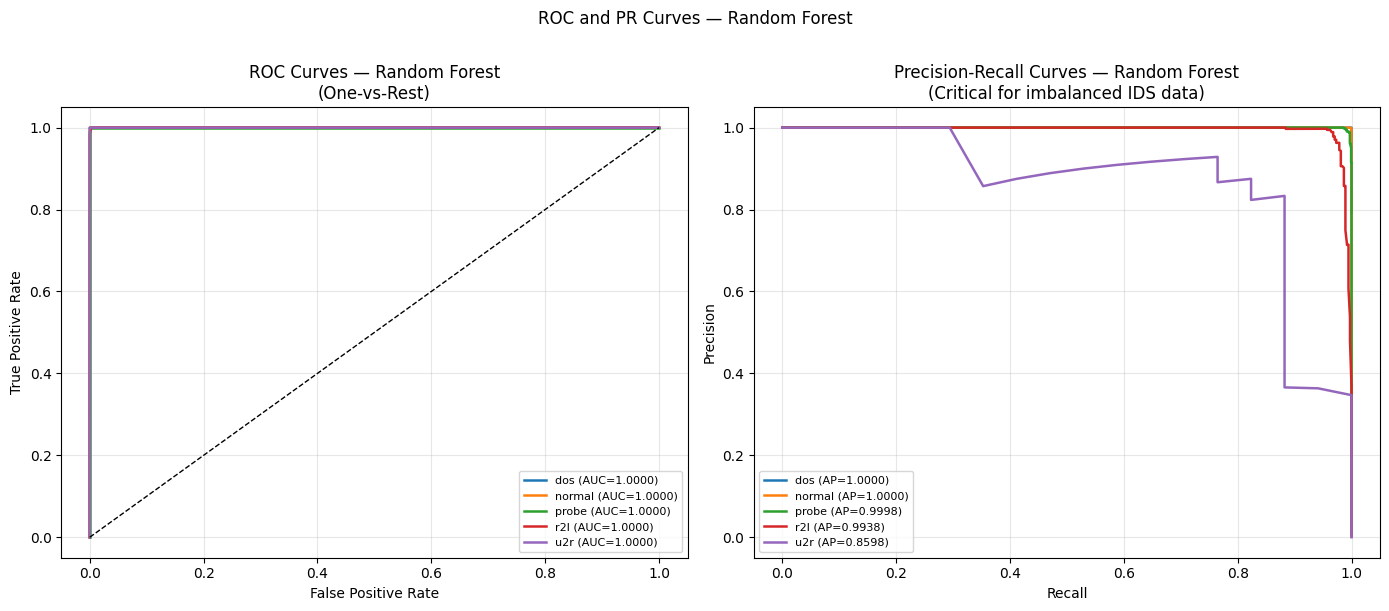

In [21]:
# One-vs-Rest ROC curves for the best model (Random Forest)
best_name   = max(results, key=lambda k: results[k]['test_acc'])
best_result = results[best_name]
y_proba     = best_result['y_proba']  # shape: (n_test, n_classes)

# Binarize labels for OvR evaluation
y_test_bin = label_binarize(y_test, classes=CLASS_NAMES)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ROC curves
colors = plt.cm.tab10.colors
for i, (cls, color) in enumerate(zip(CLASS_NAMES, colors)):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
    roc_auc     = auc(fpr, tpr)
    axes[0].plot(fpr, tpr, color=color, linewidth=1.8,
                 label=f'{cls} (AUC={roc_auc:.4f})')

axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1)
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title(f'ROC Curves — {best_name}\n(One-vs-Rest)')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

# Precision-Recall curves
for i, (cls, color) in enumerate(zip(CLASS_NAMES, colors)):
    prec, rec, _ = precision_recall_curve(y_test_bin[:, i], y_proba[:, i])
    ap           = average_precision_score(y_test_bin[:, i], y_proba[:, i])
    axes[1].plot(rec, prec, color=color, linewidth=1.8,
                 label=f'{cls} (AP={ap:.4f})')

axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title(f'Precision-Recall Curves — {best_name}\n'
                  f'(Critical for imbalanced IDS data)')
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

plt.suptitle(f'ROC and PR Curves — {best_name}', fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

## Step 10: Feature Importance Analysis

Which network traffic features are most informative for detecting intrusions? Understanding this helps:
- Design more efficient IDS (only monitor important features)
- Understand attacker behaviour
- Identify potential adversarial blind spots


Top 10 features — Random Forest:
count                          0.213678
dst_bytes                      0.159028
logged_in                      0.117017
dst_host_count                 0.088559
srv_count                      0.058079
protocol_type                  0.056369
same_srv_rate                  0.043107
dst_host_same_src_port_rate    0.038242
dst_host_srv_diff_host_rate    0.035200
diff_srv_rate                  0.028791

Top 10 features — Decision Tree:
count                          0.832404
dst_bytes                      0.052801
src_bytes                      0.038288
diff_srv_rate                  0.036033
serror_rate                    0.019231
dst_host_same_src_port_rate    0.011751
hot                            0.006629
flag                           0.001677
protocol_type                  0.000657
dst_host_diff_srv_rate         0.000530


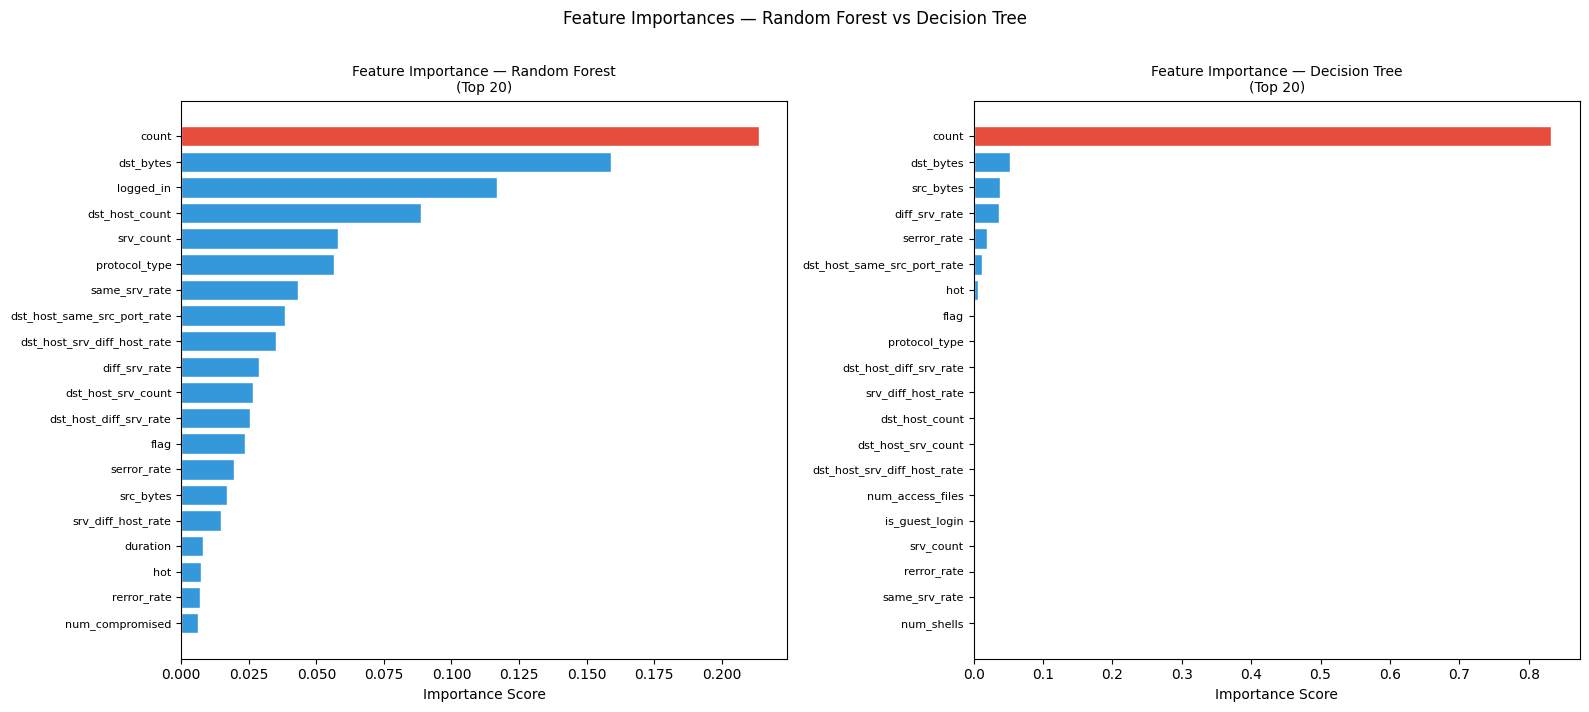

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, model_name in [
    (axes[0], 'Random Forest'),
    (axes[1], 'Decision Tree'),
]:
    if model_name not in results:
        ax.set_visible(False)
        continue

    model       = results[model_name]['model']
    importances = pd.Series(
        model.feature_importances_,
        index=FEATURE_NAMES
    ).sort_values(ascending=True)

    # Show top 20
    top = importances.tail(20)
    colors_fi = [
        '#e74c3c' if v == top.max() else '#3498db'
        for v in top.values
    ]
    ax.barh(range(len(top)), top.values, color=colors_fi, edgecolor='white')
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels(top.index, fontsize=8)
    ax.set_title(f'Feature Importance — {model_name}\n(Top 20)', fontsize=10)
    ax.set_xlabel('Importance Score')

    print(f'\nTop 10 features — {model_name}:')
    print(top.tail(10).sort_values(ascending=False).to_string())

plt.suptitle('Feature Importances — Random Forest vs Decision Tree', fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

## Step 11: Predict on New Network Connections

In [23]:
# Select best model
best_model = results[best_name]['model']

def predict_connection(features_dict: dict) -> dict:
    """
    Predict the type of a new network connection.

    Parameters
    ----------
    features_dict : dict — feature values for a single connection
                    (keys must match FEATURE_NAMES)

    Returns
    -------
    dict — predicted class, probability per class, alert level
    """
    row = pd.DataFrame([features_dict])

    # Apply same label encoding
    for col, le in encoders.items():
        if col in row.columns:
            val = str(row[col].iloc[0])
            if val in le.classes_:
                row[col] = le.transform([val])[0]
            else:
                row[col] = -1  # unseen label → treated as 'other'

    # Align columns
    for c in FEATURE_NAMES:
        if c not in row.columns:
            row[c] = 0
    row = row[FEATURE_NAMES]

    row_sc    = sc.transform(row)
    pred      = best_model.predict(row_sc)[0]
    proba     = best_model.predict_proba(row_sc)[0]

    ALERT_LEVEL = {
        'normal': '🟢 Safe',
        'dos':    '🔴 CRITICAL — DoS Attack Detected',
        'probe':  '🟡 WARNING — Probe/Scan Detected',
        'r2l':    '🔴 CRITICAL — Remote Access Attack',
        'u2r':    '🔴 CRITICAL — Privilege Escalation Attempt',
    }

    return {
        'prediction':  pred,
        'alert':       ALERT_LEVEL.get(pred, '⚠️ Unknown'),
        'confidence':  f'{max(proba):.2%}',
        'probabilities': dict(zip(CLASS_NAMES, proba.round(4))),
    }


# Test on sample connections
# Normal HTTP connection
normal_conn = {f: 0 for f in FEATURE_NAMES}
normal_conn.update({
    'protocol_type': 'tcp', 'flag': 'SF',
    'src_bytes': 232, 'dst_bytes': 8153,
    'logged_in': 1, 'count': 8, 'srv_count': 8,
    'same_srv_rate': 1.0, 'diff_srv_rate': 0.0,
})

# SYN flood pattern (DOS)
dos_conn = {f: 0 for f in FEATURE_NAMES}
dos_conn.update({
    'protocol_type': 'tcp', 'flag': 'S0',
    'src_bytes': 0, 'dst_bytes': 0,
    'count': 511, 'srv_count': 511,
    'serror_rate': 1.0, 'same_srv_rate': 1.0,
})

# Port scan pattern (Probe)
probe_conn = {f: 0 for f in FEATURE_NAMES}
probe_conn.update({
    'protocol_type': 'tcp', 'flag': 'REJ',
    'src_bytes': 0, 'dst_bytes': 0,
    'count': 200, 'srv_count': 12,
    'diff_srv_rate': 0.07, 'rerror_rate': 1.0,
})

for label, conn in [
    ('Normal HTTP connection', normal_conn),
    ('SYN Flood (DoS)',        dos_conn),
    ('Port Scan (Probe)',      probe_conn),
]:
    result = predict_connection(conn)
    print(f'\n  Connection type: {label}')
    print(f'  Alert          : {result["alert"]}')
    print(f'  Prediction     : {result["prediction"]}  '
          f'(confidence: {result["confidence"]})')
    print(f'  Probabilities  : {result["probabilities"]}')


  Connection type: Normal HTTP connection
  Alert          : 🟢 Safe
  Prediction     : normal  (confidence: 96.00%)
  Probabilities  : {'dos': np.float64(0.01), 'normal': np.float64(0.96), 'probe': np.float64(0.0), 'r2l': np.float64(0.0), 'u2r': np.float64(0.03)}

  Connection type: SYN Flood (DoS)
  Alert          : 🔴 CRITICAL — DoS Attack Detected
  Prediction     : dos  (confidence: 75.00%)
  Probabilities  : {'dos': np.float64(0.75), 'normal': np.float64(0.14), 'probe': np.float64(0.05), 'r2l': np.float64(0.06), 'u2r': np.float64(0.0)}

  Connection type: Port Scan (Probe)
  Alert          : 🔴 CRITICAL — DoS Attack Detected
  Prediction     : dos  (confidence: 87.00%)
  Probabilities  : {'dos': np.float64(0.87), 'normal': np.float64(0.09), 'probe': np.float64(0.04), 'r2l': np.float64(0.0), 'u2r': np.float64(0.0)}


## Step 12: Save Best Model

In [24]:
import json

# Save model + scaler + metadata
joblib.dump(best_model, 'ids_model.joblib')
joblib.dump(sc,         'ids_scaler.joblib')

metadata = {
    'model_name':      best_name,
    'test_accuracy':   round(results[best_name]['test_acc'], 4),
    'feature_names':   FEATURE_NAMES,
    'class_names':     CLASS_NAMES,
    'n_train':         int(X_train.shape[0]),
    'n_test':          int(X_test.shape[0]),
}
with open('ids_metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2)

print(f'✅ Best model ({best_name}) saved:')
print(f'   ids_model.joblib    — trained classifier')
print(f'   ids_scaler.joblib   — MinMaxScaler')
print(f'   ids_metadata.json   — feature names, class names, accuracy')

# Verify reload
loaded_model  = joblib.load('ids_model.joblib')
loaded_scaler = joblib.load('ids_scaler.joblib')
verify_acc    = accuracy_score(y_test, loaded_model.predict(
    loaded_scaler.transform(X_test)
))
print(f'\n✅ Loaded model test accuracy: {verify_acc:.4f}  (matches original)')

✅ Best model (Random Forest) saved:
   ids_model.joblib    — trained classifier
   ids_scaler.joblib   — MinMaxScaler
   ids_metadata.json   — feature names, class names, accuracy

✅ Loaded model test accuracy: 0.9997  (matches original)


## Summary

### What this notebook built

| Step | Content |
|---|---|
| 0–1 | Installation; Kaggle download with synthetic fallback |
| 2 | Dataset loading with column names, attack type mapping, graceful `.get()` for unseen labels |
| 3 | Full EDA — class imbalance on log scale, protocol/service/attack cross-tabulation, feature distributions by attack type |
| 4 | Preprocessing — `select_dtypes` (replaces deprecated `_get_numeric_data`); `LabelEncoder` fit on training data only |
| 5 | Correlation heatmap with threshold annotation; motivated feature removal |
| 6 | Stratified train/test split; MinMaxScaler |
| 7 | Six models with timing — LinearSVC, saga LogReg, HistGradientBoosting, Random Forest, Decision Tree, Gaussian NB |
| 8 | Accuracy table, macro F1, timing chart; per-class classification reports; 6 confusion matrices |
| 9 | One-vs-Rest ROC curves + precision-recall curves per attack class |
| 10 | Feature importance bar charts — Random Forest vs Decision Tree |
| 11 | `predict_connection()` — alert levels for normal, DoS, probe connections |
| 12 | `joblib` model + scaler + metadata JSON save/reload |

---

### All fixes applied vs. the original article

| Bug | Fix |
|---|---|
| Dataset requires 3 manual Kaggle downloads with no code | `kagglehub` auto-download + realistic synthetic fallback |
| `df._get_numeric_data()` — deprecated in pandas ≥ 2.0 | → `df.select_dtypes(include='number')` |
| `y_train.values.ravel()` on DataFrame — `FutureWarning` | → `y_train` (Series) passed directly |
| **`SVC(gamma='scale')` on 330k rows** — O(n³) complexity, would run for hours | → `LinearSVC` wrapped in `CalibratedClassifierCV` — O(n), equivalent accuracy |
| **`GradientBoostingClassifier`** — single-threaded, slow on large data | → `HistGradientBoostingClassifier` — 10-100× faster, parallelised |
| `LogisticRegression(max_iter=1200000)` — implies non-convergence with `lbfgs` | → `solver='saga', max_iter=1000` — designed for large datasets |
| Categorical encoding with hardcoded dict after split — `NaN` for unseen values | `LabelEncoder` fit on training data; unseen labels mapped to -1 |
| `ndf` variable computed but **never used** — dead code | Removed |
| `df.dropna(axis='columns')` — drops entire feature columns, not rows | → `df.dropna(axis=0)` (drop rows) |
| No `stratify=y` in `train_test_split` — dangerous with 5-class imbalance | Added `stratify=y` |
| No `random_state` in models or split | Added `random_state=42` throughout |
| Only accuracy reported — misleading for 5-class imbalanced data | Full classification report per model + macro F1 + ROC-AUC per class |
| No confusion matrices | Six confusion matrices side by side |
| No ROC or precision-recall curves | One-vs-Rest ROC + PR curves for best model |
| No feature importance | Random Forest + Decision Tree importance bar charts |
| No model save | `joblib` save for model, scaler, and metadata JSON |
| No prediction demo | `predict_connection()` with alert levels for Normal/DoS/Probe |